# Lab data reconciliation

Synthetic laboratory exports with deliberately planted inconsistencies. The golden output is hand-authored separately from the algorithm. Nothing here is a clinical or manufacturing release system.

## Setup

Run from the repository root after installing `requirements.lock`. The validation runner executes this notebook and retains a separate executed copy. All code blocks below run against the same versioned implementation.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

import analysis

OUT = Path("artifacts/run")

## 1. Define the grain and keys

Metadata has one meaning per sample_id. Export rows have record_id, sample_id and revision. Only byte-equivalent field payloads are deduplicated automatically. Conflicting record IDs, conflicting donor mappings and tied latest revisions are quarantined, not guessed.

## 2. Resolve state before values

Select the highest unique revision before testing approval, units, timestamps and biological value bounds. If that revision is pending, invalid or ambiguous, quarantine the sample. Never discard an invalid latest row and accidentally resurrect an obsolete result.

## 3. Verify units and consequences

Normalize percent to fraction exactly once. Values must be finite and within [0, 1]. Join metadata with an explicit one-to-one validation. Each original row receives exactly one disposition. Compare the selected sample-level mean with a deliberately naive approved-row mean; different eligible populations prevent a causal interpretation of that difference.

## Execute the complete analysis

Inspect the returned results and tables. No outcome is hand-written into the code or edited to create a better story.

In [2]:
summary = analysis.run(OUT)
print(json.dumps(summary, indent=2))

{
  "source": "Fully synthetic laboratory export; not clinical or manufacturing records",
  "input_rows": 18,
  "metadata_unique_sample_ids": 10,
  "canonical_samples": 4,
  "dispositions": {
    "quarantined": 12,
    "selected": 4,
    "superseded": 1,
    "duplicate": 1
  },
  "canonical_mean_viability": 0.9125,
  "naive_approved_row_mean": 0.9226666666666665,
  "mean_comparison_limit": "Different record populations; this contrast demonstrates weighting/eligibility differences, not a treatment effect.",
  "illustrative_threshold": 0.9,
  "canonical_samples_at_or_above_threshold": 3,
  "quarantine_reasons": {
    "invalid latest measurement or timestamp": 3,
    "latest revision not approved": 2,
    "ambiguous latest revision": 2,
    "conflicting record identity": 2,
    "conflicting sample metadata": 1,
    "orphan sample": 1,
    "missing sample or record identity": 1
  },
  "source_sha256": {
    "expected_canonical.csv": "d4b246cfbed4f269435f37678800f1ec5c54bd360806f06c90c156e9

In [3]:
display(pd.read_csv("data/lab_export.csv"))
display(pd.read_csv(OUT / "canonical.csv"))

,record_id,sample_id,revision,status,value,unit,measured_at
0,r01,S01,1,approved,95.00,percent,2026-01-01T00:00:00Z
1,r02,S01,2,approved,0.91,fraction,2026-01-01T00:00:00Z
2,r03,S02,1,approved,88.00,percent,2026-01-01T00:00:00Z
3,r03,S02,1,approved,88.00,percent,2026-01-01T00:00:00Z
4,r04,S03,1,approved,99.00,percent,2026-01-01T00:00:00Z
5,r05,S03,2,approved,110.00,percent,2026-01-01T00:00:00Z
6,r06,S04,1,approved,0.93,fraction,2026-01-01T00:00:00Z
7,r07,S04,2,pending,0.94,fraction,2026-01-01T00:00:00Z
8,r08,S05,1,approved,NaN,fraction,2026-01-01T00:00:00Z
9,r09,S06,1,approved,92.00,percent,2026-01-01T00:00:00Z


,sample_id,record_id,revision,viability_fraction,source_row,measured_at,donor_id,condition
0,S01,r02,2,0.91,1,2026-01-01 00:00:00+00:00,D01,control
1,S02,r03,1,0.88,2,2026-01-01 00:00:00+00:00,D01,treated
2,S06,r09,1,0.92,9,2026-01-01 00:00:00+00:00,D03,treated
3,S10,r14,1,0.94,15,2026-01-01 00:00:00+00:00,D05,treated


,source_row,record_id,sample_id,disposition,reason
0,0,r01,S01,superseded,earlier version retained in audit
1,1,r02,S01,selected,latest unique approved valid revision
2,2,r03,S02,selected,latest unique approved valid revision
3,3,r03,S02,duplicate,exact duplicate payload
4,4,r04,S03,quarantined,invalid latest measurement or timestamp
5,5,r05,S03,quarantined,invalid latest measurement or timestamp
6,6,r06,S04,quarantined,latest revision not approved
7,7,r07,S04,quarantined,latest revision not approved
8,8,r08,S05,quarantined,invalid latest measurement or timestamp
9,9,r09,S06,selected,latest unique approved valid revision


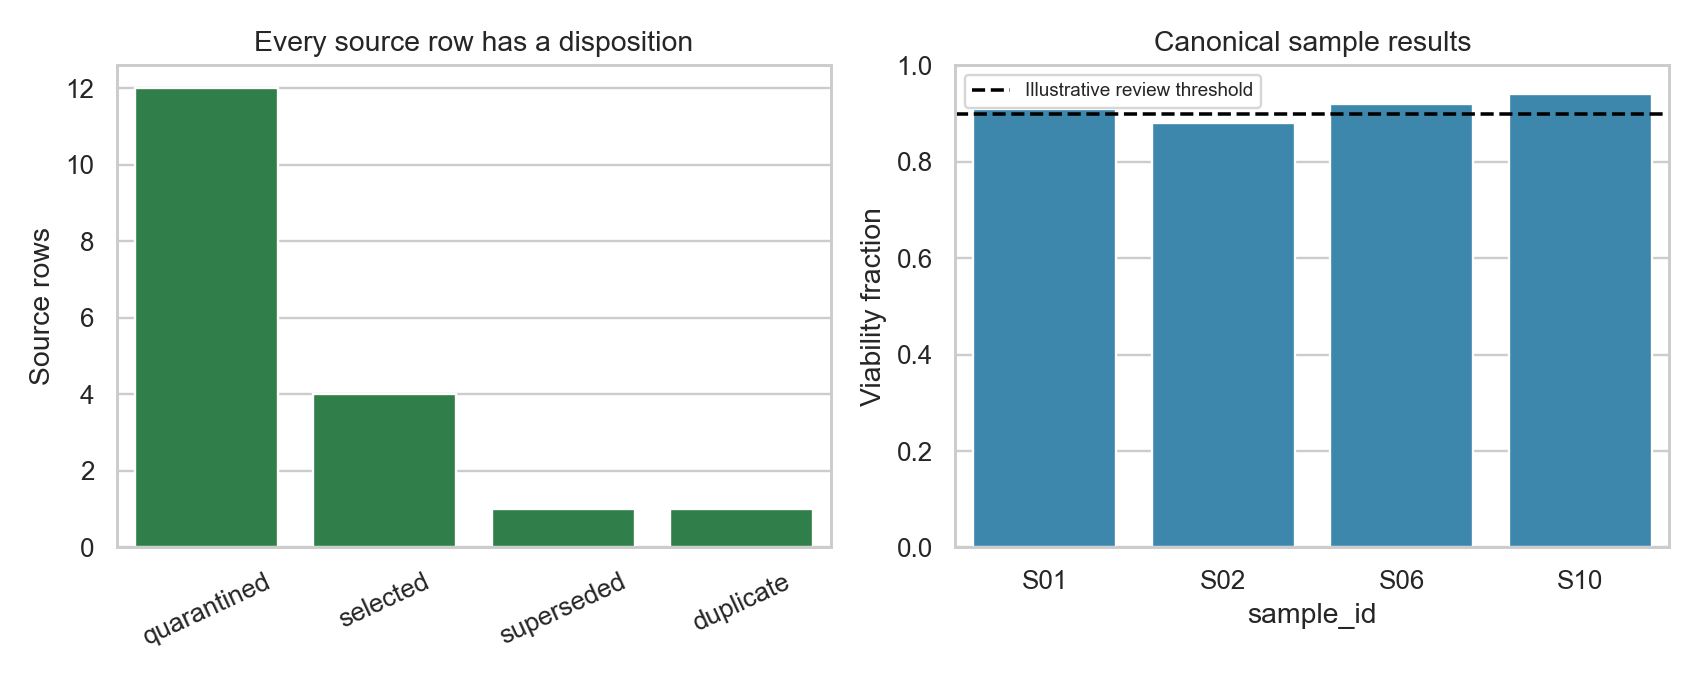

In [4]:
display(pd.read_csv(OUT / "row_audit.csv"))
display(Image(filename=str(OUT / "reconciliation.png")))

## What was validated

`tests/` checks hand-calculated examples, independent formulations, malformed inputs and relevant invariants. `python scripts/validate.py` runs pytest, the full pipeline and this notebook. Passing these checks is bounded computational evidence, not clinical validation. See `reports/reference/FINDINGS.md` for actual results and limitations.